# Multiclass classifier on IRIS **dataset**

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import label_binarize

In [ ]:
# Load the Iris dataset
iris = load_iris()
print(iris.feature_names)
X = iris.data  # Features
y = iris.target  # Labels

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [ ]:
# One-hot encode the labels: use (1,0,0), (0,1,0), (0,0,1)
y = to_categorical(y)

In [ ]:
# Split data into training (60%), test (20%), and validation (20%), stratify keep the proportion between the 3 species
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [ ]:
# Check the shapes of the datasets
print(f"Training set shape: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Validation set shape: X_val={X_val.shape}, y_val={y_val.shape}")
print(f"Test set shape: X_test={X_test.shape}, y_test={y_test.shape}")

Training set shape: X_train=(90, 4), y_train=(90, 3)
Validation set shape: X_val=(30, 4), y_val=(30, 3)
Test set shape: X_test=(30, 4), y_test=(30, 3)


In [ ]:
#remove not needed datasets to reduce memory consumption
del X_temp, y_temp, X, y

In [ ]:
# Define the neural network model
model = Sequential()

In [ ]:
# Add layers
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(16, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(y_train.shape[1], activation='softmax'))  # Output layer with 3 exits interpretabili come probabilità assegnate alle tre specie

In [ ]:
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:

# Train the model
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=32)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 337ms/step - accuracy: 0.3333 - loss: 1.7429 - val_accuracy: 0.3333 - val_loss: 1.7010
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 145ms/step - accuracy: 0.3333 - loss: 1.6610 - val_accuracy: 0.3333 - val_loss: 1.6183
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.3333 - loss: 1.5861 - val_accuracy: 0.3333 - val_loss: 1.5431
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.3333 - loss: 1.5146 - val_accuracy: 0.3000 - val_loss: 1.4755
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 159ms/step - accuracy: 0.3333 - loss: 1.4533 - val_accuracy: 0.3000 - val_loss: 1.4175
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.3333 - loss: 1.3987 - val_accuracy: 0.2667 - val_loss: 1.3672
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.3222 - loss: 1.3520 - val_accuracy: 0.3000 - val_loss: 1.3223
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.3111 - loss: 1.3095 - val_accuracy: 0.3000 - val_

In [ ]:
# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 1.0000 - loss: 0.4065
Test Loss: 0.4065
Test Accuracy: 1.0000


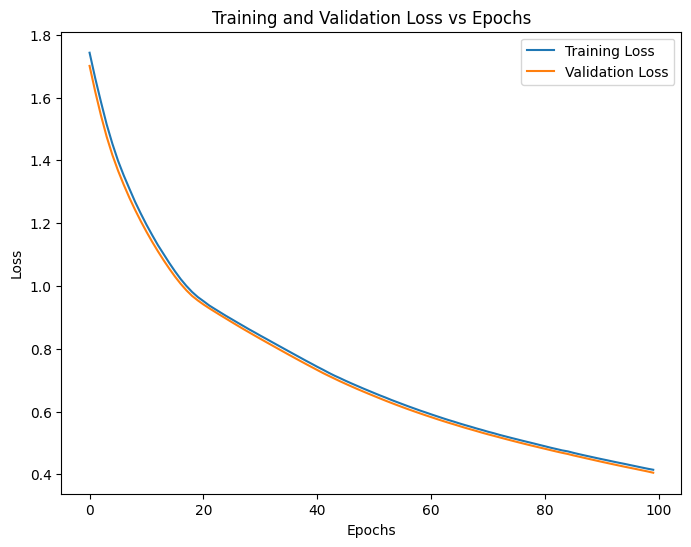

In [ ]:
# Plot training & validation loss vs epochs
plt.figure(figsize=(8,6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

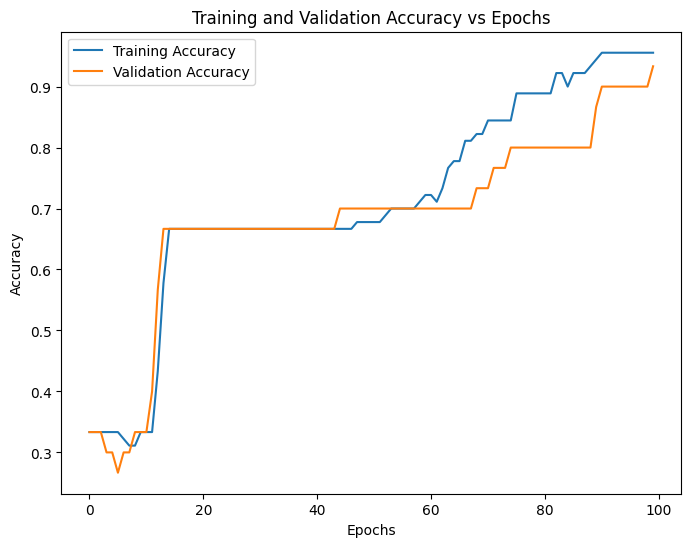

In [ ]:
# Plot training & validation loss vs epochs
plt.figure(figsize=(8,6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 1.0000 - loss: 0.4065
Test Loss: 0.4065
Test Accuracy: 1.0000


3
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


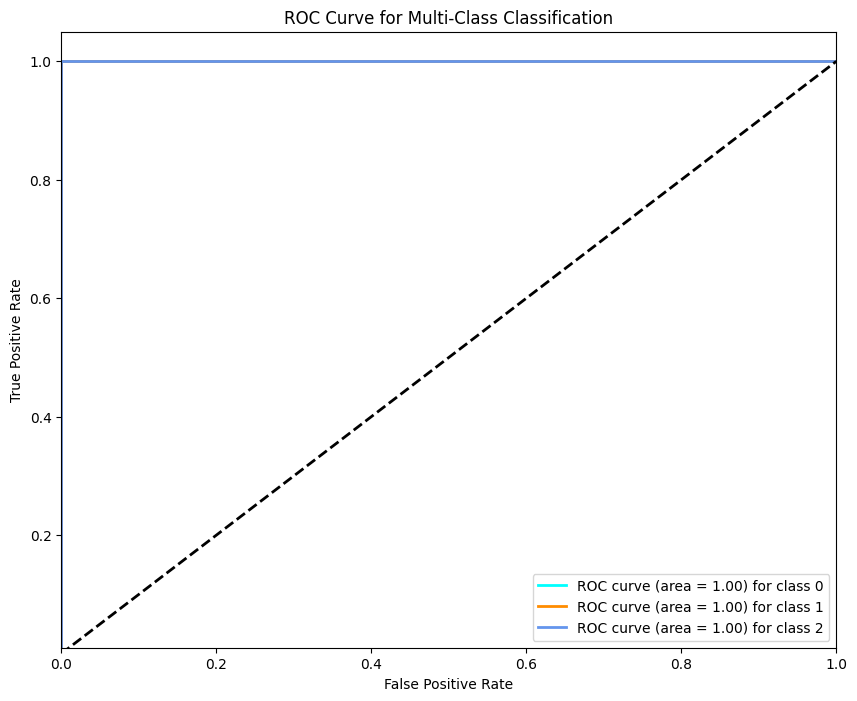

In [ ]:
# ROC curve for the test dataset (One-vs-Rest)
#print(y_test.shape)
n_classes = y_test.shape[1]
print(n_classes)

# Predict probabilities on the test set
y_score = model.predict(X_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i]) # auc: area under the curve

# Plot ROC curve for each class
plt.figure(figsize=(10, 8))
colors = ['aqua', 'darkorange', 'cornflowerblue']

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve (area = {roc_auc[i]:.2f}) for class {i}')

plt.plot([0, 1], [0, 1], 'k--', lw=2)  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.01, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Multi-Class Classification')
plt.legend(loc="lower right")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


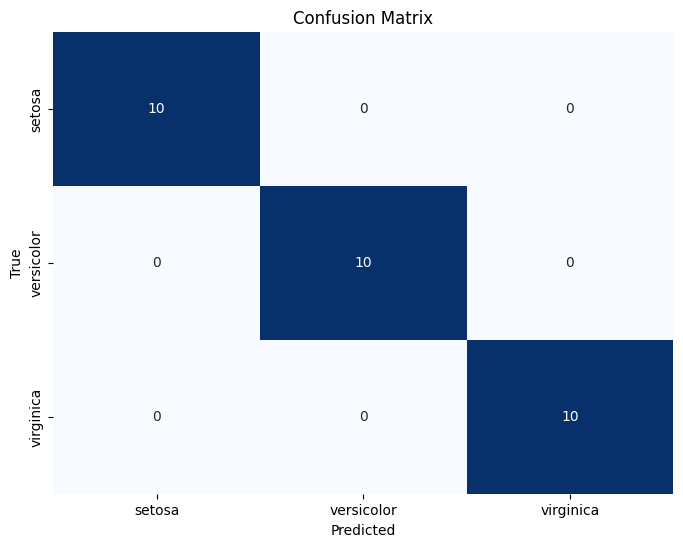

In [ ]:
# Confusion matrix for the test dataset
y_pred = np.argmax(model.predict(X_test), axis=1)  # Convert probabilities to class labels (0, 1, or 2)
y_true = np.argmax(y_test, axis=1) #Converts the true labels from one-hot encoding to class indices. For example, `[0, 1, 0]` becomes `1`.

cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix using seaborn heatmap (annot write the counts in the cellars, fmt="d" formats them as integers)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# **Binary classifier on TITANIC dataset:**

In [2]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [3]:
# Load Titanic dataset
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
titanic_data = pd.read_csv(url)

In [4]:
# Display the first few rows of the dataset
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
print(titanic_data)

     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ... 

In [6]:
# some standard processing
# Fill missing values (NaN) in 'Age' with the median age
titanic_data['Age'] = titanic_data['Age'].fillna(titanic_data['Age'].median())

# Fill missing values in 'Embarked' with the mode (most frequent value)
titanic_data['Embarked'] = titanic_data['Embarked'].fillna(titanic_data['Embarked'].mode()[0])

# Drop rows where 'Fare' is missing (if any)
titanic_data.dropna(subset=['Fare'], inplace=True)

# Drop unnecessary columns (PassengerId, Name, Ticket, Cabin)
titanic_data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'], inplace=True)

# Convert categorical features 'Sex' and 'Embarked' to numeric using LabelEncoder
label_encoder = LabelEncoder()
titanic_data['Sex'] = label_encoder.fit_transform(titanic_data['Sex'])
titanic_data['Embarked'] = label_encoder.fit_transform(titanic_data['Embarked'])

In [7]:
# Define features (X) and target (y)
X = titanic_data.drop(columns=['Survived'])
y = titanic_data['Survived']
print(X.columns.tolist())

['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [8]:
# Split the datasets into training (60%), validation (20%), and test (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

# Fit the scaler on training data only, then apply it to all three sets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [9]:
#remove not needed datasets to reduce memory consumption
del X_temp, y_temp, X, y

In [10]:
# Check the shapes of the datasets
print(f"Training set shape: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Validation set shape: X_val={X_val.shape}, y_val={y_val.shape}")
print(f"Test set shape: X_test={X_test.shape}, y_test={y_test.shape}")

Training set shape: X_train=(534, 7), y_train=(534,)
Validation set shape: X_val=(178, 7), y_val=(178,)
Test set shape: X_test=(179, 7), y_test=(179,)


In [11]:
# Define the neural network model
model_ES = Sequential()

In [12]:
# Add layers
model_ES.add(Input(shape=(X_train.shape[1],)))
model_ES.add(Dense(64, activation='relu'))
model_ES.add(Dense(64, activation='relu'))
model_ES.add(Dense(1, activation='sigmoid'))  # Probability of survival

In [13]:
# Compile the model
model_ES.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [14]:
# Train the model
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model_ES.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)
print(f"Training stopped after {len(history.history['loss'])} epochs")

Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.7097 - loss: 0.6386 - val_accuracy: 0.8090 - val_loss: 0.5656
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8146 - loss: 0.5337 - val_accuracy: 0.8034 - val_loss: 0.4861
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8090 - loss: 0.4737 - val_accuracy: 0.8090 - val_loss: 0.4306
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8109 - loss: 0.4421 - val_accuracy: 0.8090 - val_loss: 0.4098
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8090 - loss: 0.4273 - val_accuracy: 0.8427 - val_loss: 0.4005
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8221 - loss: 0.4193 - val_accuracy: 0.8315 - val_loss: 0.3980
Epoch 7/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8240 - loss: 0.4143 - val_accuracy: 0.8315 - val_loss: 0.3964
Epoch 8/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8315 - loss: 0.4102 - val_accuracy: 0.

In [15]:
#Evaluate the model on the test set
test_loss, test_accuracy = model_ES.evaluate(X_test, y_test)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8212 - loss: 0.4425 
Test Loss: 0.4425
Test Accuracy: 0.8212


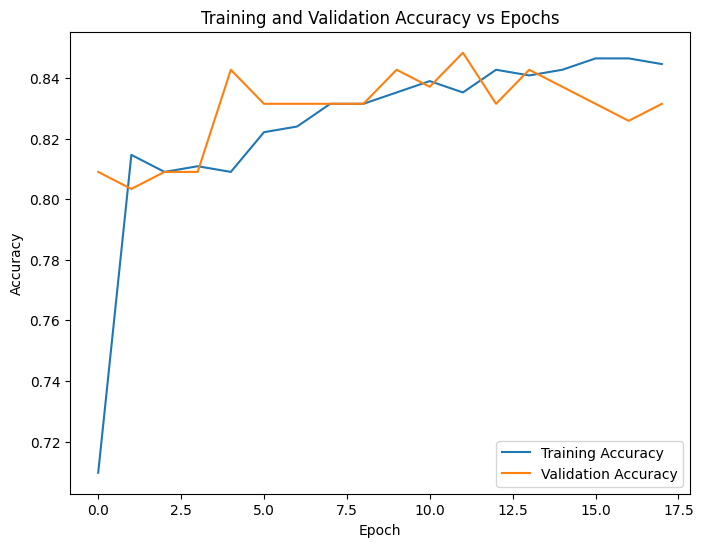

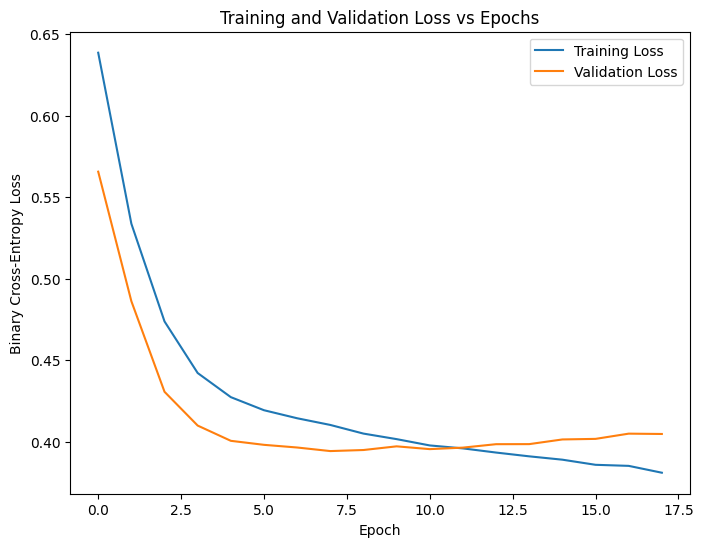

In [16]:
# Plot training and validation accuracy vs epochs
plt.figure(figsize=(8, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy vs Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss vs epochs
plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss vs Epochs')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.show()

In [17]:
# Generate predictions for the test

# Predict survival probabilities for the test set
y_score = model_ES.predict(X_test).ravel()

# Convert probabilities into class labels using a threshold of 0.5
y_pred = (y_score >= 0.5).astype(int)

print("First 10 predicted probabilities:", y_score[:10])
print("First 10 predicted classes:", y_pred[:10])

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
First 10 predicted probabilities: [0.93729943 0.88240355 0.68337905 0.10891034 0.6077917  0.7421513
 0.976692   0.1044163  0.45095703 0.25319806]
First 10 predicted classes: [1 1 1 0 1 1 1 0 0 0]


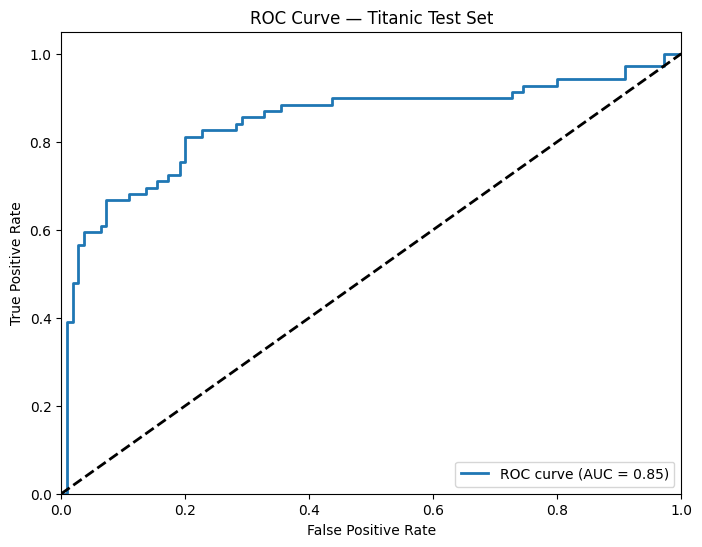

In [18]:
# Plot ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Titanic Test Set')
plt.legend(loc='lower right')
plt.show()

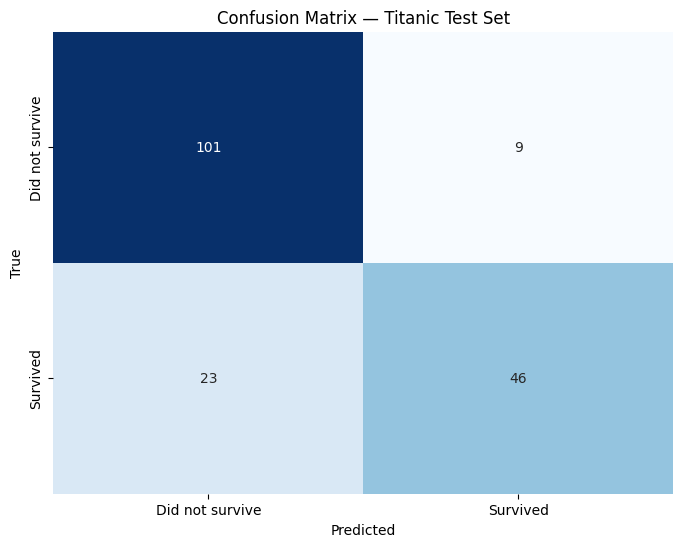

In [19]:
# Compute and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Did not survive', 'Survived'],
    yticklabels=['Did not survive', 'Survived']
)
plt.title('Confusion Matrix — Titanic Test Set')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()